In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

### MEMBACA DATASET DAN EDA

Ukuran dataset: (3501, 13)
\nInformasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3501 entries, 0 to 3500
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   periode_data               3501 non-null   int64  
 1   bulan                      3501 non-null   int64  
 2   tanggal                    3501 non-null   int64  
 3   stasiun                    3501 non-null   object 
 4   pm_sepuluh                 3237 non-null   float64
 5   pm_duakomalima             3440 non-null   float64
 6   sulfur_dioksida            3445 non-null   float64
 7   karbon_monoksida           3451 non-null   float64
 8   ozon                       3455 non-null   float64
 9   nitrogen_dioksida          3432 non-null   float64
 10  max                        3493 non-null   float64
 11  parameter_pencemar_kritis  3436 non-null   object 
 12  kategori                   3500 non-null   object 
dtype

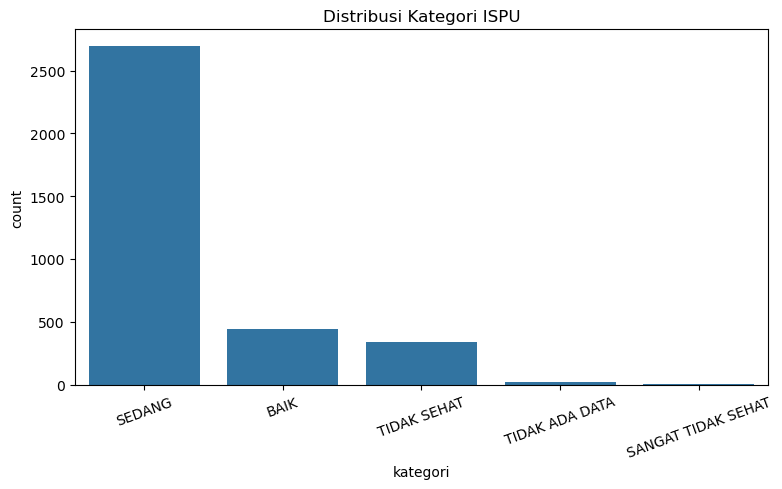

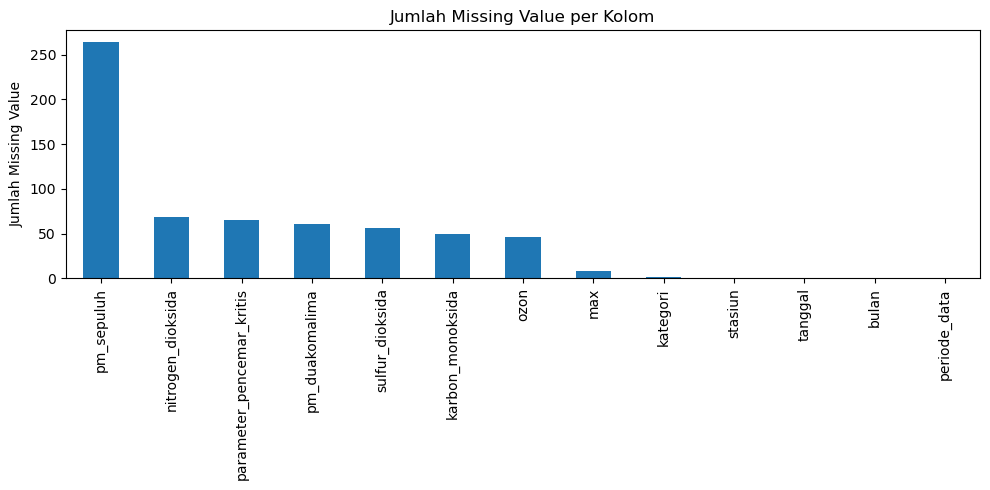

In [2]:
df = pd.read_csv("dataset.csv")

print("Ukuran dataset:", df.shape)
print("\\nInformasi dataset:")
print(df.info())

print("\\nStatistik deskriptif:")
print(df.describe(include="all"))

print("\\nMissing value setiap kolom:")
print(df.isna().sum())

print("\\nDistribusi kategori:")
print(df["kategori"].value_counts(dropna=False))

# Visualisasi distribusi kategori
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="kategori",
              order=df["kategori"].value_counts().index)
plt.title("Distribusi Kategori ISPU")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Visualisasi missing value
plt.figure(figsize=(10, 5))
df.isna().sum().sort_values(ascending=False).plot(kind="bar")
plt.title("Jumlah Missing Value per Kolom")
plt.ylabel("Jumlah Missing Value")
plt.tight_layout()
plt.show()

### PREPROCESSING

In [5]:
features = [
    "pm_sepuluh",
    "pm_duakomalima",
    "sulfur_dioksida",
    "karbon_monoksida",
    "ozon",
    "nitrogen_dioksida"
]
target = "kategori"
kelas_valid = ["BAIK", "SEDANG", "TIDAK SEHAT"]

# Memilih enam fitur dan satu target
data = df[features + [target]].copy()

# Mempertahankan tiga kelas yang digunakan dalam klasifikasi.
data = data[data[target].isin(kelas_valid)]

# Menghapus baris yang memiliki missing value pada enam fitur
data = data.dropna(subset=features + [target])

# Memeriksa duplikasi
print("Jumlah duplikasi pada data terpilih:", data.duplicated().sum())

# Data final
X = data[features]
y = data[target]

print("Jumlah data setelah preprocessing:", len(data))
print("Distribusi kelas setelah preprocessing:")
print(y.value_counts())

Jumlah duplikasi pada data terpilih: 10
Jumlah data setelah preprocessing: 3131
Distribusi kelas setelah preprocessing:
kategori
SEDANG         2451
BAIK            361
TIDAK SEHAT     319
Name: count, dtype: int64


### ANALISIS OUTLIER DENGAN METODE IQR


Tabel Analisis Outlier Metode IQR (3.131 baris):
            Fitur   Q1   Q3  IQR  Batas bawah  Batas atas  Kandidat outlier
       pm_sepuluh 37.0 60.0 23.0          2.5        94.5                 9
   pm_duakomalima 57.0 88.0 31.0         10.5       134.5                12
  sulfur_dioksida 24.0 53.0 29.0        -19.5        96.5                 0
 karbon_monoksida 10.0 19.0  9.0         -3.5        32.5                30
             ozon 14.0 29.0 15.0         -8.5        51.5               145
nitrogen_dioksida 15.0 38.0 23.0        -19.5        72.5                47


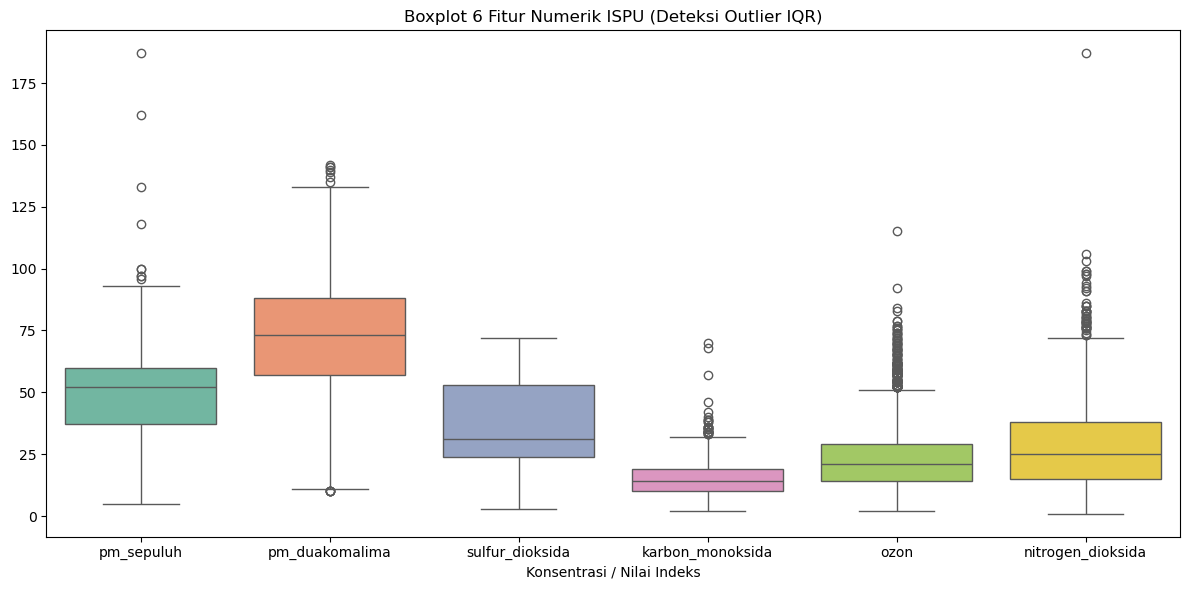

In [6]:
outlier_summary = []

for col in features:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    # Menghitung kandidat outlier di luar batas bawah dan batas atas
    n_outliers = ((data[col] < lower_bound) | (data[col] > upper_bound)).sum()
    
    outlier_summary.append({
        "Fitur": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Batas bawah": round(lower_bound, 2),
        "Batas atas": round(upper_bound, 2),
        "Kandidat outlier": n_outliers
    })

df_outlier = pd.DataFrame(outlier_summary)
print("\nTabel Analisis Outlier Metode IQR (3.131 baris):")
print(df_outlier.to_string(index=False))

plt.figure(figsize=(12, 6))
sns.boxplot(data=data[features], orient="v", palette="Set2")
plt.title("Boxplot 6 Fitur Numerik ISPU (Deteksi Outlier IQR)")
plt.xlabel("Konsentrasi / Nilai Indeks")
plt.tight_layout()
plt.show()

## PERHITUNGAN 15 DATA TERPILIH

In [7]:
scaler_manual = MinMaxScaler()
X_scaled_all = pd.DataFrame(
    scaler_manual.fit_transform(X),
    columns=features,
    index=X.index
)

data_baru = pd.DataFrame([{
    "pm_sepuluh": 55,
    "pm_duakomalima": 78,
    "sulfur_dioksida": 35,
    "karbon_monoksida": 15,
    "ozon": 24,
    "nitrogen_dioksida": 28
}])

data_baru_scaled = scaler_manual.transform(data_baru)[0]

# Mengambil 15 baris acak, random_state menjaga hasil tetap sama
sampel_15 = data.sample(n=15, random_state=42)
sampel_scaled = X_scaled_all.loc[sampel_15.index]

# Menghitung Euclidean Distance enam fitur
jarak = np.sqrt(
    ((sampel_scaled.values - data_baru_scaled) ** 2).sum(axis=1)
)

hasil_manual = sampel_scaled.copy()
hasil_manual.insert(0, "data_ke", sampel_15.index + 1)
hasil_manual["jarak"] = jarak
hasil_manual["kategori"] = y.loc[sampel_15.index]

print("\\n15 data sampel setelah scaling dan jaraknya:")
print(hasil_manual.to_string(index=False))

hasil_urut = hasil_manual.sort_values("jarak")
print("\\n15 data setelah diurutkan berdasarkan jarak:")
print(hasil_urut[["data_ke", "jarak", "kategori"]].to_string(index=False))

K = 5
tetangga_terdekat = hasil_urut.head(K)
print("\\nLima tetangga terdekat:")
print(tetangga_terdekat[["data_ke", "jarak", "kategori"]])

print("\\nVoting:")
print(tetangga_terdekat["kategori"].value_counts())

prediksi_manual = tetangga_terdekat["kategori"].mode()[0]
print("Prediksi data baru:", prediksi_manual)

\n15 data sampel setelah scaling dan jaraknya:
 data_ke  pm_sepuluh  pm_duakomalima  sulfur_dioksida  karbon_monoksida     ozon  nitrogen_dioksida    jarak    kategori
    1815    0.208791        0.454545         0.333333          0.132353 0.221239           0.112903 0.173894      SEDANG
    2790    0.406593        0.795455         0.550725          0.220588 0.150442           0.043011 0.341728 TIDAK SEHAT
     189    0.225275        0.393939         0.318841          0.073529 0.088496           0.037634 0.273536      SEDANG
    1603    0.373626        0.590909         0.898551          0.323529 0.185841           0.526882 0.606517      SEDANG
    3015    0.038462        0.295455         0.260870          0.058824 0.238938           0.118280 0.406759        BAIK
    1435    0.071429        0.416667         0.753623          0.411765 0.292035           0.145161 0.439522      SEDANG
    1125    0.203297        0.348485         0.797101          0.132353 0.115044           0.118280 0.3930

### EVALUASI

\nAkurasi model: 0.9362041467304625
\nClassification report:
              precision    recall  f1-score   support

        BAIK       0.88      0.83      0.86        72
      SEDANG       0.95      0.97      0.96       491
 TIDAK SEHAT       0.85      0.83      0.84        64

    accuracy                           0.94       627
   macro avg       0.90      0.88      0.89       627
weighted avg       0.94      0.94      0.94       627



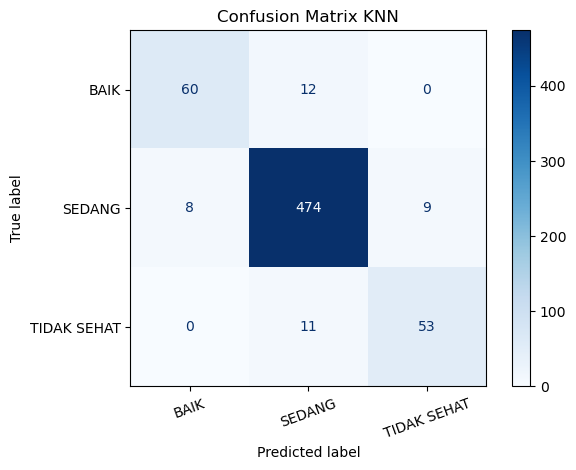

\nPrediksi data baru oleh model KNN: SEDANG


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler_model = MinMaxScaler()
X_train_scaled = scaler_model.fit_transform(X_train)
X_test_scaled = scaler_model.transform(X_test)

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("\\nAkurasi model:", accuracy_score(y_test, y_pred))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=kelas_valid)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=kelas_valid
)
disp.plot(cmap="Blues", xticks_rotation=20)
plt.title("Confusion Matrix KNN")
plt.tight_layout()
plt.show()

data_baru_model_scaled = scaler_model.transform(data_baru)
prediksi_model = knn.predict(data_baru_model_scaled)

print("\\nPrediksi data baru oleh model KNN:", prediksi_model[0])